# Lab 2 — Improving a CNN on CIFAR-10

Starting from the Lab 1 CNN, this lab tests three changes independently:

1. **Batch normalization** after each convolution.
2. **Dropout** in the fully connected classifier.
3. **Greater depth** with a third convolutional block.

All models use the same data split, optimizer, batch size, and number of epochs. Validation accuracy is measured on 5,000 images held out from the CIFAR-10 training set; the official test set is not used for model selection.

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

seed = 42
torch.manual_seed(seed)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('torch', torch.__version__, ' device', device)

torch 2.14.1  device mps


## 1. Training and validation data

A fixed random seed makes the 45,000/5,000 split reproducible. No data augmentation is used, so any accuracy change comes from the model architecture rather than a different training pipeline.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

full_train_ds = datasets.CIFAR10(
    './data', train=True, download=True, transform=transform
)
train_ds, val_ds = random_split(
    full_train_ds,
    [45_000, 5_000],
    generator=torch.Generator().manual_seed(seed),
)
val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)

print('training samples  :', len(train_ds))
print('validation samples:', len(val_ds))
print('classes           :', full_train_ds.classes)

training samples  : 45000
validation samples: 5000
classes           : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 2. Baseline and improved models

The baseline reproduces Lab 1: two `Conv → ReLU → MaxPool` blocks followed by a fully connected classifier. Each experiment enables only one change:

- **Batch normalization:** `Conv → BatchNorm → ReLU → MaxPool`.
- **Dropout:** `Dropout(0.5)` after the hidden classifier activation.
- **Deeper:** a third 128-channel convolutional block, reducing spatial size to 4×4.

In [3]:
class CNN(nn.Module):
    def __init__(self, use_batch_norm=False, use_dropout=False, deeper=False):
        super().__init__()
        block_channels = [32, 64, 128] if deeper else [32, 64]
        layers = []
        in_channels = 3

        for out_channels in block_channels:
            layers.append(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
            )
            if use_batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
            in_channels = out_channels

        self.features = nn.Sequential(*layers)
        spatial_size = 32 // (2 ** len(block_channels))
        classifier_layers = [
            nn.Flatten(),
            nn.Linear(in_channels * spatial_size * spatial_size, 128),
            nn.ReLU(),
        ]
        if use_dropout:
            classifier_layers.append(nn.Dropout(0.5))
        classifier_layers.append(nn.Linear(128, 10))
        self.classifier = nn.Sequential(*classifier_layers)

    def forward(self, x):
        return self.classifier(self.features(x))


configs = {
    'Baseline': {},
    'Batch normalization': {'use_batch_norm': True},
    'Dropout (p=0.5)': {'use_dropout': True},
    'Deeper (3 conv blocks)': {'deeper': True},
}

for name, kwargs in configs.items():
    model = CNN(**kwargs)
    parameters = sum(p.numel() for p in model.parameters())
    print(f'{name:26s} {parameters:,} parameters')

Baseline                   545,098 parameters
Batch normalization        545,290 parameters
Dropout (p=0.5)            545,098 parameters
Deeper (3 conv blocks)     356,810 parameters


## 3. Controlled training experiment

Every model is trained for 10 epochs with SGD (`lr=0.05`, `momentum=0.9`) and batch size 128, matching Lab 1. The model and shuffle generators are reseeded before every run so each experiment sees the same batch order.

In [4]:
epochs = 10
batch_size = 128


def evaluate(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += criterion(logits, yb).item() * xb.size(0)
            total_correct += (logits.argmax(1) == yb).sum().item()
            total_samples += xb.size(0)

    return total_loss / total_samples, total_correct / total_samples


def run_experiment(model_kwargs):
    torch.manual_seed(seed)
    model = CNN(**model_kwargs).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    shuffle_generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        generator=shuffle_generator,
    )
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_samples = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * xb.size(0)
            total_samples += xb.size(0)

        train_loss = total_loss / total_samples
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        print(
            f'epoch {epoch + 1:2d}  train_loss {train_loss:.4f}  '
            f'val_loss {val_loss:.4f}  val_acc {val_acc * 100:.2f}%'
        )

    return history

In [5]:
results = {}

for name, kwargs in configs.items():
    print(f'\n=== {name} ===')
    results[name] = run_experiment(kwargs)


=== Baseline ===


epoch  1  train_loss 1.4846  val_loss 1.1311  val_acc 59.28%


epoch  2  train_loss 1.0155  val_loss 0.9529  val_acc 66.78%


epoch  3  train_loss 0.8261  val_loss 0.8548  val_acc 70.00%


epoch  4  train_loss 0.6773  val_loss 0.9171  val_acc 68.60%


...

epoch  6  train_loss 0.5212  val_loss 0.7966  val_acc 74.06%


epoch  7  train_loss 0.4449  val_loss 0.8473  val_acc 74.10%


epoch  8  train_loss 0.3928  val_loss 0.9231  val_acc 72.96%


epoch  9  train_loss 0.3700  val_loss 0.9722  val_acc 72.60%


epoch 10  train_loss 0.3237  val_loss 1.0839  val_acc 72.78%


## 4. Validation-accuracy comparison

**Best validation accuracy** is the primary comparison because final-epoch accuracy can decline when a model overfits. Change is measured in percentage points relative to the baseline's best validation accuracy.

In [6]:
baseline_best = max(results['Baseline']['val_acc']) * 100

print(
    f'{"Model":26s} {"Best val":>10s} {"Best epoch":>11s} '
    f'{"Final val":>10s} {"Change (pp)":>12s}'
)
print('-' * 75)
for name, history in results.items():
    best_acc = max(history['val_acc']) * 100
    best_epoch = history['val_acc'].index(max(history['val_acc'])) + 1
    final_acc = history['val_acc'][-1] * 100
    change = best_acc - baseline_best
    print(
        f'{name:26s} {best_acc:9.2f}% {best_epoch:11d} '
        f'{final_acc:9.2f}% {change:+11.2f}'
    )

best_name = max(results, key=lambda name: max(results[name]['val_acc']))
best_acc = max(results[best_name]['val_acc']) * 100
print(f'\nBest validation result: {best_name} at {best_acc:.2f}%')

Model                        Best val  Best epoch  Final val  Change (pp)
---------------------------------------------------------------------------
Baseline                       71.44%           5     68.52%       +0.00
Batch normalization            71.96%           8     71.26%       +0.52
Dropout (p=0.5)                71.16%           8     69.90%       -0.28
Deeper (3 conv blocks)         74.10%           7     72.78%       +2.66

Best validation result: Deeper (3 conv blocks) at 74.10%


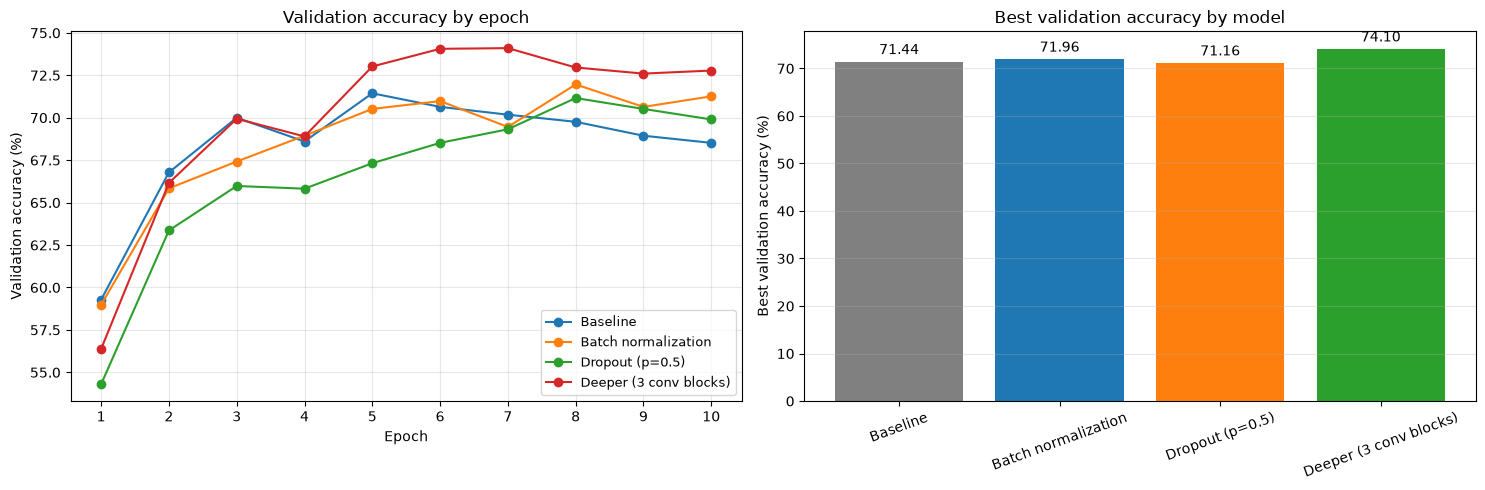

In [7]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
epoch_numbers = range(1, epochs + 1)

for name, history in results.items():
    axes[0].plot(
        epoch_numbers,
        [acc * 100 for acc in history['val_acc']],
        marker='o',
        label=name,
    )

axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Validation accuracy (%)')
axes[0].set_title('Validation accuracy by epoch')
axes[0].set_xticks(list(epoch_numbers))
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=9)

names = list(results)
best_accuracies = [max(results[name]['val_acc']) * 100 for name in names]
bars = axes[1].bar(names, best_accuracies, color=['gray', 'tab:blue', 'tab:orange', 'tab:green'])
axes[1].bar_label(bars, fmt='%.2f', padding=3)
axes[1].set_ylabel('Best validation accuracy (%)')
axes[1].set_title('Best validation accuracy by model')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Conclusion

In this run, **increasing depth gave the highest best validation accuracy: 74.10%**, an improvement of **2.66 percentage points** over the baseline's 71.44%. **Batch normalization** reached 71.96% (+0.52 points), while **dropout** reached 71.16% (−0.28 points), so dropout did not improve best validation accuracy within 10 epochs.

These are single 10-epoch runs, so the results support a comparison under this setup rather than a universal ranking of the techniques. Repeating the experiments with several seeds would make the conclusions more reliable.